In [2]:
import pandas as pd
data=pd.read_csv(r"D:\HOPEAI\DS\Data Science-Univate\Week5-Data Science-Univate\Univariate Analysis\Placement.csv")
data.sample()

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
176,177,F,59.0,Central,60.0,Others,Commerce,56.0,Comm&Mgmt,No,55.0,Mkt&HR,57.9,Placed,220000.0


In [3]:
import warnings
warnings.filterwarnings("ignore")

In [4]:
data.shape

(215, 15)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    object 
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    object 
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    object 
 6   hsc_s           215 non-null    object 
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    object 
 9   workex          215 non-null    object 
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    object 
 12  mba_p           215 non-null    float64
 13  status          215 non-null    object 
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), object(8)
memory usage: 25.3+ KB


In [6]:
numerical=[]
categorical=[]
for col in data.columns:
    if data[col].dtype=="object":
        categorical.append(col)
    else:
        numerical.append(col)

In [7]:
numerical

['sl_no', 'ssc_p', 'hsc_p', 'degree_p', 'etest_p', 'mba_p', 'salary']

In [8]:
categorical

['gender',
 'ssc_b',
 'hsc_b',
 'hsc_s',
 'degree_t',
 'workex',
 'specialisation',
 'status']

In [9]:
data.describe()

,sl_no,ssc_p,hsc_p,degree_p,etest_p,mba_p,salary
count,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,148.000000
mean,108.000000,67.303395,66.333163,66.370186,72.100558,62.278186,288655.405405
std,62.209324,10.827205,10.897509,7.358743,13.275956,5.833385,93457.452420
min,1.000000,40.890000,37.000000,50.000000,50.000000,51.210000,200000.000000
25%,54.500000,60.600000,60.900000,61.000000,60.000000,57.945000,240000.000000
50%,108.000000,67.000000,65.000000,66.000000,71.000000,62.000000,265000.000000
75%,161.500000,75.700000,73.000000,72.000000,83.500000,66.255000,300000.000000
max,215.000000,89.400000,97.700000,91.000000,98.000000,77.890000,940000.000000


In [10]:
data["ssc_p"].mean()

67.30339534883721

In [11]:
mct=pd.DataFrame(index=["Mean","Median","Mode","Q1:25%","Q2:50%","Q3:75%","Q4:100%","IQR","LesserOutlier","GreaterOutlier","Min","Max"],columns=['sl_no', 'ssc_p', 'hsc_p', 'degree_p', 'etest_p', 'mba_p', 'salary'])
import numpy as np
for col in numerical:
    mct[col]["Mean"]=data[col].mean()
    mct[col]["Median"]=data[col].median()
    mct[col]["Mode"]=data[col].mode()[0]
    mct[col]["Q1:25%"]=np.percentile(data[col],25)
    mct[col]["Q2:50%"]=np.percentile(data[col],50)
    mct[col]["Q3:75%"]=data[col].quantile(.75)
    mct[col]["Q4:100%"]=np.percentile(data[col],100)
    mct[col]["IQR"]=mct[col]["Q3:75%"]-mct[col]["Q1:25%"]
    mct[col]["LesserOutlier"]=mct[col]["Q1:25%"]-1.5*mct[col]["IQR"]
    mct[col]["GreaterOutlier"]=mct[col]["Q3:75%"]+1.5*mct[col]["IQR"]
    mct[col]["Min"]=data[col].min()
    mct[col]["Max"]=data[col].max()
    
    
    

In [12]:
mct

,sl_no,ssc_p,hsc_p,degree_p,etest_p,mba_p,salary
Mean,108.0,67.303395,66.333163,66.370186,72.100558,62.278186,288655.405405
Median,108.0,67.0,65.0,66.0,71.0,62.0,265000.0
Mode,1,62.0,63.0,65.0,60.0,56.7,300000.0
Q1:25%,54.5,60.6,60.9,61.0,60.0,57.945,NaN
Q2:50%,108.0,67.0,65.0,66.0,71.0,62.0,NaN
Q3:75%,161.5,75.7,73.0,72.0,83.5,66.255,300000.0
Q4:100%,215.0,89.4,97.7,91.0,98.0,77.89,NaN
IQR,107.0,15.1,12.1,11.0,23.5,8.31,NaN
LesserOutlier,-106.0,37.95,42.75,44.5,24.75,45.48,NaN
GreaterOutlier,322.0,98.35,91.15,88.5,118.75,78.72,NaN


### Finding Outliers

In [13]:
lesser=[]
greater=[]
for col in numerical:
    if mct[col]["LesserOutlier"]> mct[col]["Min"]:
        lesser.append(col)
    if mct[col]["GreaterOutlier"]< mct[col]["Max"]:
        greater.append(col)
        

In [14]:
lesser

['hsc_p']

In [15]:
greater

['hsc_p', 'degree_p']

In [16]:
for col in numerical:
    lower=mct.loc["LesserOutlier",col]
    upper=mct.loc["GreaterOutlier",col]
    data[col]=data[col].clip(lower=lower,upper=upper)

#clip() automatically replaces values outside the boundaries.

In [17]:
#for col in lesser:
#    data[col][mct[col]["LesserOutlier"]> mct[col]["Min"]]=mct[col]["LesserOutlier"]
#for col in greater:
#    data[col][mct[col]["GreaterOutlier"]< mct[col]["Max"]]=mct[col]["GreaterOutlier"]

In [18]:
mct=pd.DataFrame(index=["Mean","Median","Mode","Q1:25%","Q2:50%","Q3:75%","Q4:100%","IQR","LesserOutlier","GreaterOutlier","Min","Max"],columns=['sl_no', 'ssc_p', 'hsc_p', 'degree_p', 'etest_p', 'mba_p', 'salary'])
import numpy as np
for col in numerical:
    mct[col]["Mean"]=data[col].mean()
    mct[col]["Median"]=data[col].median()
    mct[col]["Mode"]=data[col].mode()[0]
    mct[col]["Q1:25%"]=np.percentile(data[col],25)
    mct[col]["Q2:50%"]=np.percentile(data[col],50)
    mct[col]["Q3:75%"]=data[col].quantile(.75)
    mct[col]["Q4:100%"]=np.percentile(data[col],100)
    mct[col]["IQR"]=mct[col]["Q3:75%"]-mct[col]["Q1:25%"]
    mct[col]["LesserOutlier"]=mct[col]["Q1:25%"]-1.5*mct[col]["IQR"]
    mct[col]["GreaterOutlier"]=mct[col]["Q3:75%"]+1.5*mct[col]["IQR"]
    mct[col]["Min"]=data[col].min()
    mct[col]["Max"]=data[col].max()
    
    
    

In [19]:
lesser=[]
greater=[]
for col in numerical:
    if mct[col]["LesserOutlier"]> mct[col]["Min"]:
        lesser.append(col)
    if mct[col]["GreaterOutlier"]< mct[col]["Max"]:
        greater.append(col)
        

In [20]:
lesser

[]

In [21]:
greater

[]

In [28]:
Freq_Table=pd.DataFrame(columns=["Count","RelativeFreq","Cumsum"])

In [32]:
Freq_Table["Count"]=data["ssc_p"].value_counts()

In [33]:
Freq_Table["RelativeFreq"]=Freq_Table["Count"]/Freq_Table["Count"].sum()

In [34]:
Freq_Table["Cumsum"]=Freq_Table["RelativeFreq"].cumsum()

In [35]:
Freq_Table


,Count,RelativeFreq,Cumsum
ssc_p,,,
62.00,11,0.051163,0.051163
63.00,10,0.046512,0.097674
67.00,9,0.041860,0.139535
52.00,9,0.041860,0.181395
73.00,9,0.041860,0.223256
...,...,...,...
69.70,1,0.004651,0.981395
80.92,1,0.004651,0.986047
83.00,1,0.004651,0.990698


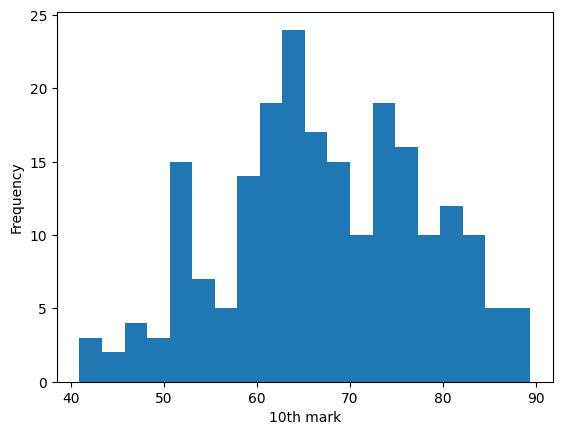

In [38]:
import matplotlib.pyplot as plt

plt.hist(data["ssc_p"],bins=20)
plt.xlabel("10th mark")
plt.ylabel("Frequency")
plt.show()

In [39]:
data["ssc_p"].kurt()

-0.6075102066986688

In [40]:
data["ssc_p"].skew()

-0.13264949031456927

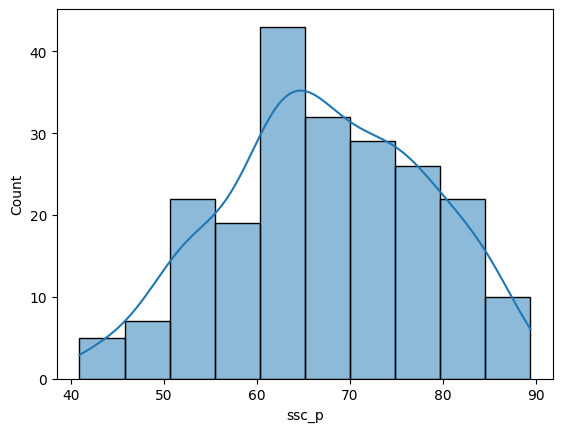

In [41]:
import seaborn as sns
sns.histplot(data["ssc_p"],kde=True)
plt.show()

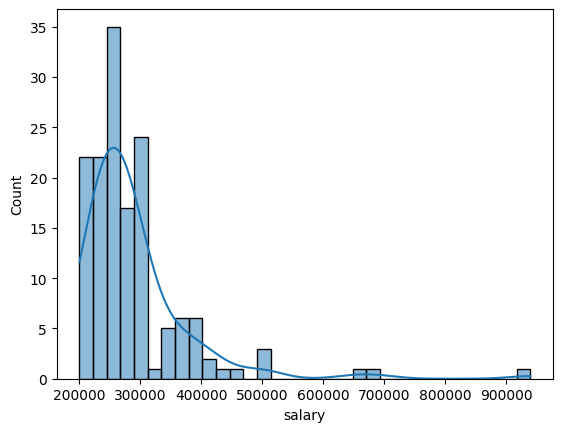

In [42]:
sns.histplot(data['salary'], kde=True)
plt.show()

In [43]:
data["salary"].skew()

3.5697471998711054